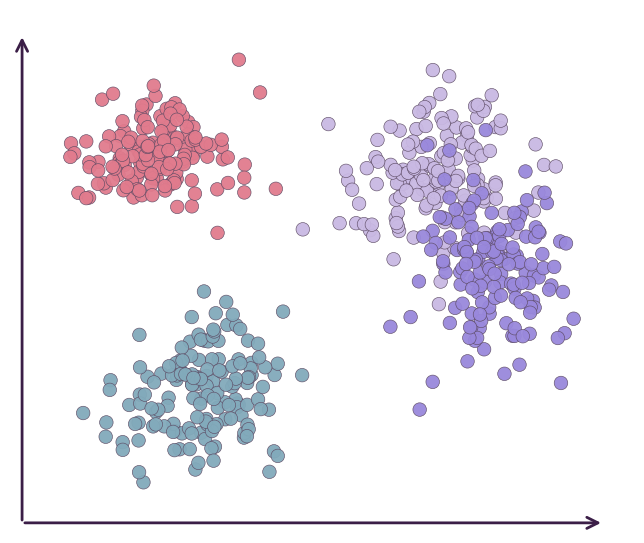

In [2]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from math import erfc, sqrt

rng = np.random.default_rng(42)
n_per_cluster = 150

# Two well-separated clusters (left side)
c1 = rng.multivariate_normal(mean=[-3.8, 1.5], cov=[[0.5, 0.00], [0.00, 0.2]], size=n_per_cluster)
c2 = rng.multivariate_normal(mean=[-3.0, -1.9], cov=[[0.5, -0.00], [-0.00, 0.3]], size=n_per_cluster)

# Two close clusters (right side): #9988DC and #C9B9E3
c3 = rng.multivariate_normal(mean=[1, 1.2], cov=[[0.50, 0.08], [0.08, 0.42]], size=n_per_cluster)
c4 = rng.multivariate_normal(mean=[2, -0.2], cov=[[0.50, -0.05], [-0.05, 0.42]], size=n_per_cluster)

coords = np.vstack([c1, c2, c3, c4])
labels = (
    ["#E17B8D"] * n_per_cluster
    + ["#C9B9E3"] * n_per_cluster
    + ["#82AABB"] * n_per_cluster
    + ["#9988DC"] * n_per_cluster
)

df = pd.DataFrame(coords, columns=["UMAP1", "UMAP2"])
df["cluster"] = labels

sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(6.6, 5.6))

sns.scatterplot(
    data=df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette=["#E17B8D", "#82AABB", "#C9B9E3", "#9988DC"],
    s=95,
    edgecolor="#5C4A63",
    linewidth=0.45,
    alpha=0.95,
    legend=False,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# Minimal axis arrows to mimic symbolic UMAP style
x_min, x_max = df["UMAP1"].min(), df["UMAP1"].max()
y_min, y_max = df["UMAP2"].min(), df["UMAP2"].max()
pad_x = (x_max - x_min) * 0.12
pad_y = (y_max - y_min) * 0.12
ax.set_xlim(x_min - pad_x, x_max + pad_x)
ax.set_ylim(y_min - pad_y, y_max + pad_y)

arrow_color = "#3B1E47"
origin_x = x_min - 0.8 * pad_x
origin_y = y_min - 0.8 * pad_y
ax.annotate("", xy=(x_max + 0.5 * pad_x, origin_y), xytext=(origin_x, origin_y),
            arrowprops=dict(arrowstyle="->", lw=2, color=arrow_color, mutation_scale=20))
ax.annotate("", xy=(origin_x, y_max + 0.5 * pad_y), xytext=(origin_x, origin_y),
            arrowprops=dict(arrowstyle="->", lw=2, color=arrow_color, mutation_scale=20))

plt.tight_layout()
plt.savefig("../figures/1_umap.pdf")
plt.show()


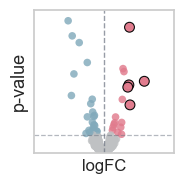

In [45]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math
rng = np.random.default_rng(7)
n_points = 300

# DE-style synthetic volcano: effect size + gene-specific uncertainty
is_de = rng.random(n_points) < 0.18
log2fc = rng.normal(0.0, 0.35, n_points)
log2fc[is_de] += rng.normal(0.0, 1.25, is_de.sum())
log2fc = np.clip(log2fc, -4.2, 4.2)

se = rng.uniform(0.18, 0.55, n_points)
z = np.abs(log2fc) / se
pval = np.array([math.erfc(val / math.sqrt(2.0)) for val in z])
neglog10p = -np.log10(np.clip(pval, 1e-16, 1.0))

df_volcano = pd.DataFrame({
    "log2FC": log2fc,
    "neglog10p": neglog10p,
})

p_thresh = 1.3  # -log10(0.05)
best_p_thresh = 3.3
best_fc_thresh = 1.4
df_volcano["group"] = "Not Sig"
df_volcano.loc[(df_volcano["neglog10p"] >= p_thresh) & (df_volcano["log2FC"] < 0), "group"] = "Down"
df_volcano.loc[(df_volcano["neglog10p"] >= p_thresh) & (df_volcano["log2FC"] > 0), "group"] = "Up"
df_volcano["selected"] = (df_volcano["log2FC"] >= best_fc_thresh) & (df_volcano["neglog10p"] >= best_p_thresh)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(2, 2))

sns.scatterplot(
    data=df_volcano,
    x="log2FC",
    y="neglog10p",
    hue="group",
    hue_order=["Not Sig", "Down", "Up"],
    palette={"Not Sig": "#BFC1C3", "Down": "#82AABB", "Up": "#E17B8D"},
    s=30,
    alpha=0.82,
    linewidth=0,
    legend=False,
    ax=ax,
)

sns.scatterplot(
    data=df_volcano[df_volcano["selected"]],
    x="log2FC",
    y="neglog10p",
    hue="group",
    hue_order=["Down", "Up"],
    palette={"Down": "#82AABB", "Up": "#E17B8D"},
    s=50,
    alpha=0.95,
    edgecolor="black",
    linewidth=0.8,
    legend=False,
    ax=ax,
)

ax.set_xlabel("logFC", fontsize=12)
ax.set_ylabel("p-value", fontsize=13)
ax.axvline(0, color="#6B7280", linewidth=1.0, linestyle="--", alpha=0.7)
ax.axhline(p_thresh, color="#6B7280", linewidth=0.9, linestyle="--", alpha=0.5)
ax.set_xlim(-4.2, 4.2)
ax.set_ylim(0, 10)
ax.grid(True, linewidth=0.8, alpha=0.28)
ax.set_axisbelow(True)
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(bottom=False, left=False)

plt.savefig("../figures/1_volcano.pdf")
plt.tight_layout()
plt.show()


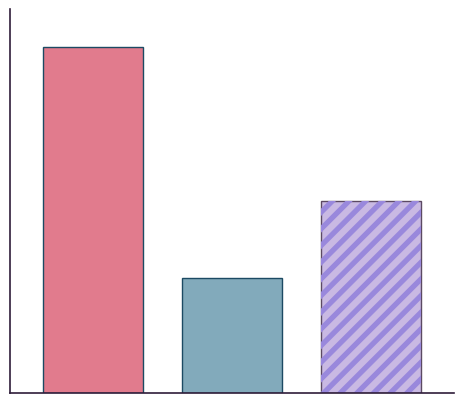

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Symbolic fractions
fractions = [0.45, 0.15, 0.40]
x = np.array([0.0, 1.0, 2.0])
width = 0.72

fig, ax = plt.subplots(figsize=(4.8, 4.2))
plt.rcParams["hatch.linewidth"] = 3.8

# Single-type bars
ax.bar(x[0], fractions[0], width=width, color="#E17B8D", edgecolor="#1C4A63", linewidth=1.0)
ax.bar(x[1], fractions[1], width=width, color="#82AABB", edgecolor="#1C4A63", linewidth=1.0)

# Intermingled bar (diagonal hatch)
ax.bar(x[2], fractions[2], width=width, color="#C9B9E3", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[2], fractions[2], width=width, color="none", edgecolor="#9988DC", linewidth=0.0, hatch="//")

ax.set_xlim(-0.6, 2.6)
ax.set_ylim(0, 0.5)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.spines["left"].set_color("#2F1D3A")
ax.spines["bottom"].set_color("#2F1D3A")

plt.tight_layout()

plt.savefig("../figures/1_band.pdf")
plt.show()


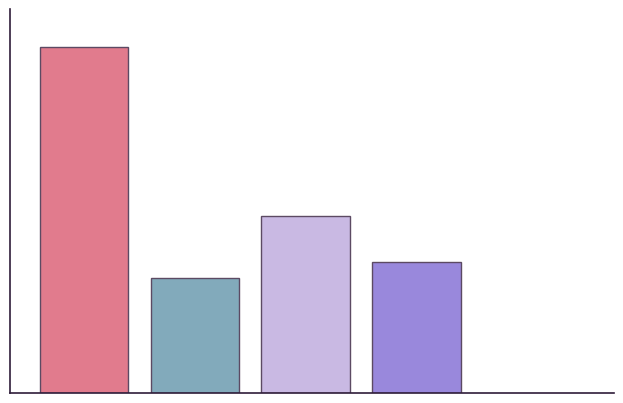

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Symbolic fractions
fractions = [0.45, 0.15, 0.23,0.17 ]
x = np.array([0.0, 0.9, 1.8, 2.7, 3.6])
width = 0.72

fig, ax = plt.subplots(figsize=(6.4, 4.2))

ax.bar(x[0], fractions[0], width=width, color="#E17B8D", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[1], fractions[1], width=width, color="#82AABB", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[2], fractions[2], width=width, color="#C9B9E3", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[3], fractions[3], width=width, color="#9988DC", edgecolor="#5C4A63", linewidth=1.0)


ax.set_xlim(-0.6, 4.3)
ax.set_ylim(0, 0.5)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.spines["left"].set_color("#2F1D3A")
ax.spines["bottom"].set_color("#2F1D3A")

plt.tight_layout()

plt.savefig("../figures/1_band_wu.pdf")
plt.show()


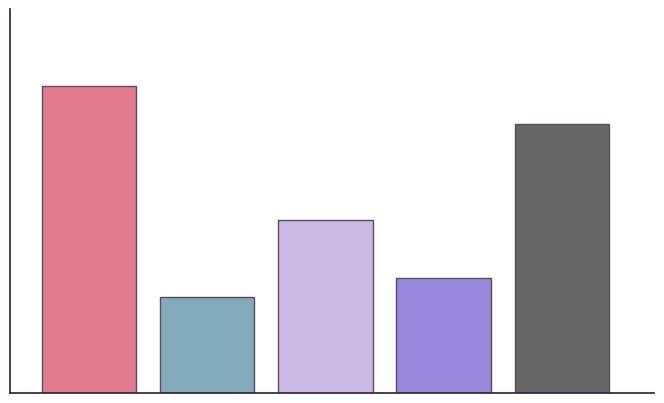

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Symbolic fractions
fractions = [0.32, 0.10, 0.18, 0.12, 0.28]
x = np.array([0.0, 0.9, 1.8, 2.7, 3.6])
width = 0.72

fig, ax = plt.subplots(figsize=(6.8, 4.2))

ax.bar(x[0], fractions[0], width=width, color="#E17B8D", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[1], fractions[1], width=width, color="#82AABB", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[2], fractions[2], width=width, color="#C9B9E3", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[3], fractions[3], width=width, color="#9988DC", edgecolor="#5C4A63", linewidth=1.0)
ax.bar(x[4], fractions[4], width=width, color="#666666", edgecolor="#5C4A63", linewidth=1.0)


ax.set_xlim(-0.6, 4.3)
ax.set_ylim(0, 0.4)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.spines["left"].set_color("#2F1D3A")
ax.spines["bottom"].set_color("#2F1D3A")

plt.tight_layout()

plt.savefig("../figures/1_band_u.pdf")
plt.show()


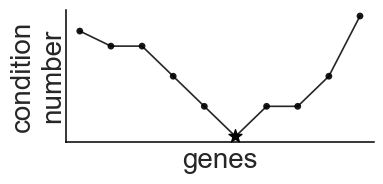

In [13]:
import matplotlib.pyplot as plt

condition_numbers = [
 295.5, 295, 295,294,293,292,293,293,294,296
]

sample_idx = np.linspace(0, len(condition_numbers) - 1, 10, dtype=int)
x = np.arange(len(sample_idx))
y = np.array([condition_numbers[i] for i in sample_idx])
best_i = int(np.argmin(y))

fig, ax = plt.subplots(figsize=(4, 2))

# Simplified symbolic curve
ax.plot(x, y, color="black", linewidth=1.2, alpha=0.85)
ax.scatter(x, y, s=24, color="black", alpha=0.9, edgecolor="none")

# Highlight best solution (lowest condition number)
ax.scatter([best_i], [y[best_i]], s=95, color="black", marker="*", zorder=4)

ax.set_xlabel("genes", fontsize=20)
ax.set_ylabel("condition\nnumber", rotation=90, labelpad=20, va="center", fontsize=20)

# Symbolic clean look
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.spines["left"].set_linewidth(1.1)
ax.spines["bottom"].set_linewidth(1.1)
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(length=0)

plt.tight_layout()
plt.savefig("../figures/1_cond.pdf")
plt.show()
